# Exploratory analysis — Madrid (A) and Sevilla (B)

Team ISD · Region: Spain (EUR) · Inside Airbnb `listings.csv.gz`, snapshots **Madrid 2026-09-17**, **Sevilla 2026-09-25**.
City C (Barcelona) is deliberately **not** looked at here.

## Summary

**What we now know**
- **Grain and size.** One row = one listing on the snapshot date. Madrid has 23 109 listings from 8 704 hosts; Sevilla has 8 375 from 3 014. `id` is unique, and the raw file has 90 columns.
- **Price coverage.** 18.7% of Madrid listings and 7.8% of Sevilla listings have no `price`. The gaps are **not random**: inactive listings (no availability in the next year and no reviews in 12 months) have no price 99% of the time in Madrid and 83% in Sevilla. Active listings miss a price only 9% and 5% of the time.
- **Price levels.** Both cities sit at almost the same level: median 151 EUR in Madrid, 158 in Sevilla. Room type and guest count drive most of the price. An entire home costs about 2.2× a private room. The price rises almost linearly with `accommodates`, from about 50 EUR for 1 guest to about 470 EUR for 10.
- **Outliers.** Less than 1% of priced listings cost above 1 000 EUR/night, and they reach up to 36 883 EUR. Most look parked or mistyped: 60% have no reviews in the last year, and many are 1–2-bedroom flats at 15 000 EUR. We flag them (`outlier_class`), train on `ok` rows only, and report test MAE both with and without them.
- **Location.** Location matters. The median price falls from about 180 EUR within 1 km of the centre to about 115 EUR at 4–8 km. The exception is Sevilla's outskirts, where country houses push prices back up.
- **Leaks.** Several 2026 columns leak the target. `price_quote_price_per_night` equals `price` for 100% of rows. `estimated_revenue_l365d` is exactly `price × estimated_occupancy_l365d`. They and the other quote columns are excluded (section 6).
- **Dead columns.** `host_since` and `instant_bookable` are completely empty in these files. The numeric `bathrooms` column is empty too; we parse `bathrooms_text` instead.

**What we still do not know**
- **Booking prices.** We only know the *advertised* price on one date, not what guests actually paid. Prices also change with season and day of week, and `calendar.csv.gz` (not used) would show that.
- **Missing prices.** We do not know why some *active* listings have no price (9% in Madrid). It could be a scraping gap or listings hidden from search.
- **High prices.** We cannot tell whether a 1 000–3 000 EUR listing is a genuine luxury flat or a typo without looking at it.
- **Transfer to another city.** Neighbourhood names, the city centre and the mix of mid-term (30+ night) rentals are city-specific. Madrid has 12% mid-term rentals, Sevilla 2%. How well a model trained on these two cities transfers to a third is open; that is what the city C run will test.


## 0. Setup
Runs unchanged on Databricks (reads the Unity Catalog tables written by the pipeline) and locally (reads the parquet lake written by `scripts/run_local.py`). Run the pipeline for Madrid and Sevilla first.

In [1]:
import os, sys, json
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = os.path.abspath("..")
sys.path.insert(0, os.path.join(REPO, "src"))
IN_DATABRICKS = "DATABRICKS_RUNTIME_VERSION" in os.environ
MODE = "delta" if IN_DATABRICKS else "local"
if not IN_DATABRICKS:
    os.environ.setdefault("AIRBNB_LOCAL_LAKE", os.path.join(REPO, "local_lake"))
    os.environ.setdefault("PYSPARK_PYTHON", sys.executable)
    from pyspark.sql import SparkSession
    spark = SparkSession.builder.master("local[4]").config("spark.driver.memory", "4g").config("spark.ui.enabled", "false").getOrCreate()
    spark.sparkContext.setLogLevel("ERROR")

from airbnb import io
from airbnb.config import load_cities
from airbnb.paths import BRONZE, SILVER
from airbnb.silver import MIN_PRICE, MAX_PRICE
from airbnb.features import assign_split

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
plt.rcParams["figure.figsize"] = (10, 4)
CITIES = ["madrid", "sevilla"]
cfg = load_cities(os.path.join(REPO, "config", "cities.yml"))
# split = the same deterministic train/test split the model uses (features.assign_split)
silver = assign_split(io.read_table(spark, SILVER, MODE).filter(f"city in ('madrid','sevilla')")).toPandas()
bronze_cols = io.read_table(spark, BRONZE, MODE).columns
print(MODE, silver.shape)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/11 21:54:41 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


local (31484, 50)


## 1. The dataset
**Source:** Inside Airbnb (CC BY 4.0), `listings.csv.gz` (detailed listings), latest snapshot per city.

**Grain:** one row = one Airbnb listing as scraped on the snapshot date (`id` is unique per city and snapshot). `price` is the nightly price the listing advertised on that date, in EUR.

In [2]:
ds = pd.DataFrame({
    "snapshot_date": {c: cfg[c].snapshot for c in CITIES},
    "listings (rows)": silver.groupby("city").size(),
    "unique ids": silver.groupby("city").id.nunique(),
    "hosts": silver.groupby("city").host_id.nunique(),
    "listings with price": silver.groupby("city").price.count(),
})
ds["raw columns"] = len([c for c in bronze_cols if c not in ("city", "snapshot_date", "source_file", "ingested_at")])
ds

,snapshot_date,listings (rows),unique ids,hosts,listings with price,raw columns
madrid,2026-09-17,23109,23109,8704,18785,90
sevilla,2026-09-25,8375,8375,3014,7723,90


## 2. Column profile
Types and missing-value rates of the silver columns we use (silver keeps every row; nothing is filtered there).

In [3]:
prof = pd.DataFrame({"dtype": silver.dtypes.astype(str)})
for c in CITIES:
    prof[f"missing_{c}"] = silver[silver.city == c].isna().mean().round(3)
prof = prof.drop(index=["amenities_raw"])
prof.sort_values("missing_madrid", ascending=False).head(25)

,dtype,missing_madrid,missing_sevilla
leak_price_quote_price_per_night,float64,0.214,0.085
price,float64,0.187,0.078
leak_estimated_revenue_l365d,float64,0.187,0.078
last_review,object,0.165,0.080
reviews_per_month,float64,0.165,0.080
first_review,object,0.165,0.080
review_scores_location,float64,0.165,0.080
review_scores_value,float64,0.165,0.080
review_scores_checkin,float64,0.165,0.080
review_scores_cleanliness,float64,0.165,0.080


Two source columns are **completely empty** in the 2026 files: `host_since` and `instant_bookable` (100% blank in both cities, see the raw check below), so the pipeline does not use them; host tenure comes from `hosts_time_as_host_years` instead.

In [4]:
raw = io.read_table(spark, BRONZE, MODE).filter("city in ('madrid','sevilla')").select("host_since", "instant_bookable", "hosts_time_as_host_years").toPandas()
raw.isna().mean().round(3)

host_since                  1.0
instant_bookable            1.0
hosts_time_as_host_years    0.0
dtype: float64

### 2.1 Missing-value *patterns*
Missingness is not random. Three blocks:
1. **Reviews block** (`review_scores_*`, `first_review`, `last_review`, `reviews_per_month`) — missing together, exactly when `number_of_reviews = 0`: no review, no score. Structural, not an error.
2. **Price** — missing for 18.7% (Madrid) / 7.8% (Sevilla). Concentrated in listings that look inactive: no availability in the next year and no reviews in the last 12 months.
3. **`minimum_nights` / `maximum_nights`** — missing together, mostly for listings with zero availability.

In [5]:
s = silver.copy()
s["no_reviews"] = s.number_of_reviews == 0
print("review_scores_rating missing == no reviews:",
      (s.review_scores_rating.isna() == s.no_reviews).mean().round(4))
s["inactive"] = (s.availability_365 == 0) & (s.number_of_reviews_ltm == 0)
tab = s.groupby(["city", "inactive"]).agg(listings=("id", "size"), price_missing_rate=("price_missing", "mean")).round(3)
tab

review_scores_rating missing == no reviews: 1.0


listings  price_missing_rate
city    inactive                              
madrid  False        20640               0.091
        True          2469               0.989
sevilla False         8067               0.049
        True           308               0.831

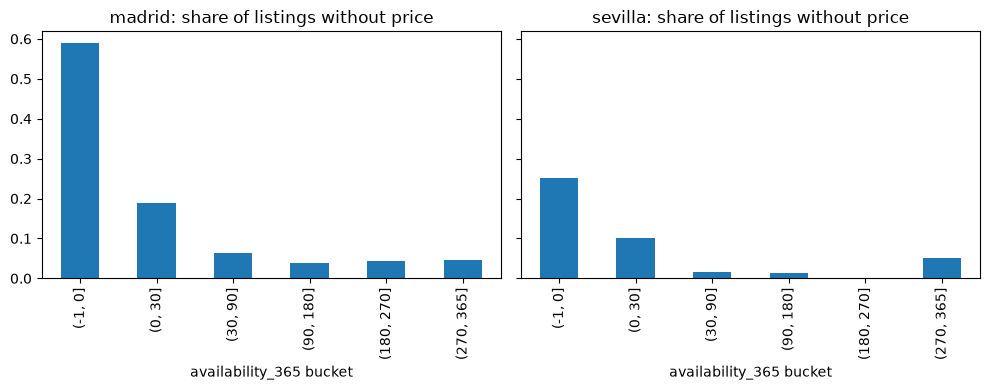

In [6]:
fig, axes = plt.subplots(1, 2, sharey=True)
for ax, c in zip(axes, CITIES):
    d = s[s.city == c]
    d.groupby(pd.cut(d.availability_365, [-1, 0, 30, 90, 180, 270, 365])).price_missing.mean().plot.bar(ax=ax)
    ax.set_title(f"{c}: share of listings without price"); ax.set_xlabel("availability_365 bucket")
plt.tight_layout(); plt.show()

In [7]:
s.groupby(s.minimum_nights.isna()).agg(listings=("id", "size"), median_availability_365=("availability_365", "median"), price_missing_rate=("price_missing", "mean")).round(3)

,listings,median_availability_365,price_missing_rate
minimum_nights,,,
False,28265,178.0,0.166
True,3219,0.0,0.092


**Decision:** rows without price stay in silver (they are real listings and count in the dashboard), but cannot be used to train or evaluate the model (no target). Because they are mostly inactive listings, the model is a model of *active* listings — stated as a limitation.

## 3. Distributions: price and availability

In [8]:
p = s[s.price.notna()]
p.groupby("city").price.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99, .999]).round(1)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,99.9%,max
city,,,,,,,,,,,,,
madrid,18785.0,208.6,543.6,9.1,24.2,38.5,95.4,151.0,224.5,471.5,969.6,9189.0,36883.0
sevilla,7723.0,203.0,274.8,10.6,36.1,64.5,118.5,158.0,220.0,418.9,999.8,3924.2,7968.5


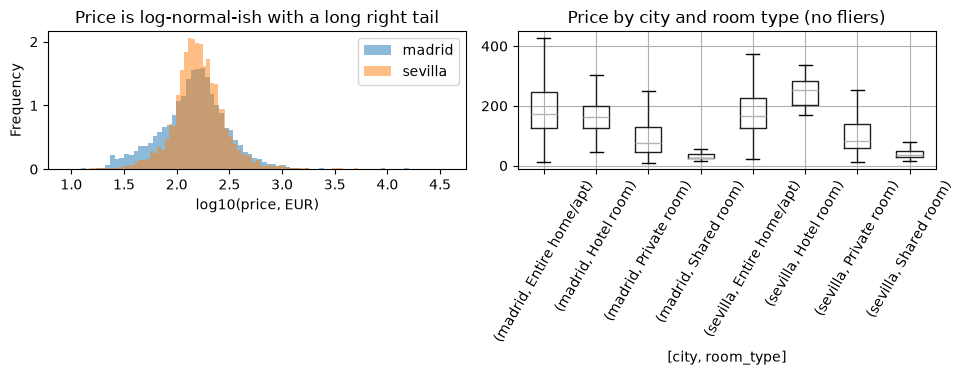

In [9]:
fig, axes = plt.subplots(1, 2)
for c in CITIES:
    np.log10(p[p.city == c].price.clip(lower=1)).plot.hist(bins=80, alpha=.5, ax=axes[0], label=c, density=True)
axes[0].set_xlabel("log10(price, EUR)"); axes[0].legend(); axes[0].set_title("Price is log-normal-ish with a long right tail")
p.boxplot(column="price", by=["city", "room_type"], ax=axes[1], rot=60, showfliers=False)
axes[1].set_title("Price by city and room type (no fliers)"); plt.suptitle(""); plt.tight_layout(); plt.show()

In [10]:
p.groupby(["city", "room_type"]).price.agg(["count", "median", "mean"]).round(1)

count  median   mean
city    room_type                            
madrid  Entire home/apt  13561   173.6  234.6
        Hotel room          29   162.0  174.3
        Private room      5059    74.0  142.9
        Shared room        136    27.0   74.8
sevilla Entire home/apt   6733   165.0  214.2
        Hotel room          17   252.0  271.4
        Private room       950    83.0  126.7
        Shared room         23    35.0   38.9

In [11]:
p.groupby(["city", "accommodates"]).price.median().unstack(0).loc[1:10].round(0)

city,madrid,sevilla
accommodates,,
1,47.0,54.0
2,122.0,123.0
3,150.0,142.0
4,176.0,161.0
5,197.0,183.0
6,243.0,208.0
7,306.0,250.0
8,325.0,292.0
9,401.0,399.0


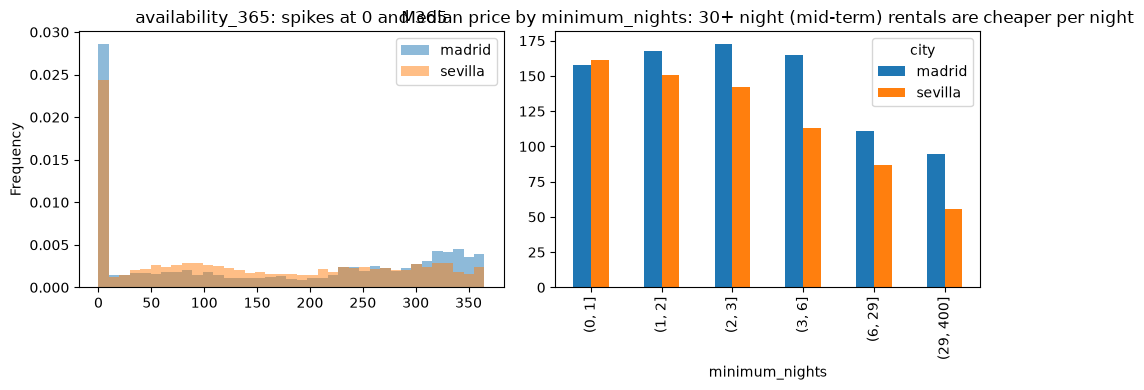

In [12]:
fig, axes = plt.subplots(1, 2)
for c in CITIES:
    s[s.city == c].availability_365.plot.hist(bins=37, alpha=.5, ax=axes[0], label=c, density=True)
axes[0].legend(); axes[0].set_title("availability_365: spikes at 0 and 365")
(p.groupby(["city", pd.cut(p.minimum_nights, [0, 1, 2, 3, 6, 29, 400])]).price.median().unstack(0)).plot.bar(ax=axes[1])
axes[1].set_title("Median price by minimum_nights: 30+ night (mid-term) rentals are cheaper per night")
plt.tight_layout(); plt.show()

## 4. Outliers
We classify, we do not delete. Classes (column `outlier_class` in silver):

| class | rule | why |
|---|---|---|
| `no_price` | price missing | no target |
| `zero_or_tiny` | price < MIN_PRICE (10 EUR) | not a real nightly price (placeholder) |
| `extreme_high` | price > MAX_PRICE (1000 EUR) | see below |
| `ok` | otherwise | |

In [13]:
pd.crosstab(s.city, s.outlier_class, margins=True)

outlier_class,extreme_high,no_price,ok,zero_or_tiny,All
city,,,,,
madrid,164,4324,18620,1,23109
sevilla,69,652,7654,0,8375
All,233,4976,26274,1,31484


In [14]:
hi = p[p.price > MAX_PRICE]
print("share of priced listings above", MAX_PRICE, ":", round(len(hi) / len(p), 4))
hi.assign(no_reviews_ltm=hi.number_of_reviews_ltm == 0, nearly_always_available=hi.availability_365 > 300)[
    ["no_reviews_ltm", "nearly_always_available"]].mean().round(2)

share of priced listings above 1000.0 : 0.0088


no_reviews_ltm             0.60
nearly_always_available    0.48
dtype: float64

In [15]:
hi.sort_values("price", ascending=False)[["city", "room_type", "accommodates", "bedrooms", "price", "availability_365", "number_of_reviews_ltm"]].head(10)

,city,room_type,accommodates,bedrooms,price,availability_365,number_of_reviews_ltm
6046,madrid,Entire home/apt,6,3.0,36883.0,351,0
17978,madrid,Entire home/apt,4,1.0,15000.0,365,0
17972,madrid,Private room,2,1.0,15000.0,365,0
17980,madrid,Private room,2,1.0,15000.0,365,0
17827,madrid,Entire home/apt,7,2.0,15000.0,365,0
17981,madrid,Private room,2,1.0,15000.0,365,0
17983,madrid,Private room,3,1.0,15000.0,365,0
17986,madrid,Private room,2,1.0,15000.0,364,0
18024,madrid,Entire home/apt,3,1.0,15000.0,365,0
18025,madrid,Entire home/apt,4,1.0,15000.0,365,0


Listings above 1000 EUR/night are less than 1% of priced listings; most never get booked (no reviews in the last year) and are open almost all year. Many are 1-2-bedroom flats at 5 000-36 000 EUR — a parked or mistyped price, not a market price. **Decision:** the model trains on `ok` rows only; the test-set metrics are reported on `ok` rows (primary) **and** on all priced rows (to show what the outliers would do to MAE).

## 5. Cleaning and transformations the pipeline applies

| # | transformation (silver) | reason |
|---|---|---|
| 1 | read CSV with `multiLine`, `escape='"'` | descriptions contain line breaks and doubled quotes; a naive read splits rows (row count checked = source count) |
| 2 | `price`: strip `$` and `,`, cast to double; blank → null | stored as text like `$1,234.00` |
| 3 | `bathrooms` from `bathrooms_text` (`"1.5 shared baths"` → 1.5 + `bathrooms_shared`; `"Half-bath"` → 0.5) | numeric `bathrooms` column is 100% empty |
| 4 | `t`/`f` → boolean | Inside Airbnb booleans are text |
| 5 | numbers with `try_cast`; blank → null | source mixes blanks and numbers; a failed cast must not kill the job |
| 6 | `amenities` JSON → `amenities_count` (+ selected amenity flags in features) | raw is a JSON array as text |
| 7 | `license` → `license_class` (registered / exempt / pending / none) | free text in Spanish/English |
| 8 | `host_years` from `hosts_time_as_host_years` | `host_since` is empty in 2026 files |
| 9 | drop `host_since`, `instant_bookable` | 100% empty |
| 10 | flags `price_missing`, `outlier_class`; no rows dropped | keep listings for the dashboard, let the model step choose its rows |
| 11 | price-derived columns renamed `leak_*` | kept only for this review, never features (section 6) |

## 6. Leakage review
Which columns must not be used to predict `price`? Some columns in the 2026 files are **computed from the price**.

In [16]:
q = p[p.leak_price_quote_price_per_night.notna()]
print("price_quote_price_per_night / price  -> quantiles:", (q.leak_price_quote_price_per_night / q.price).quantile([.01, .5, .99]).round(4).to_dict())
e = p[p.leak_estimated_occupancy_l365d > 0]
print("estimated_revenue_l365d / (price * estimated_occupancy_l365d) -> quantiles:",
      (e.leak_estimated_revenue_l365d / (e.price * e.leak_estimated_occupancy_l365d)).quantile([.01, .5, .99]).round(4).to_dict())

price_quote_price_per_night / price  -> quantiles: {0.01: 1.0, 0.5: 1.0, 0.99: 1.0}
estimated_revenue_l365d / (price * estimated_occupancy_l365d) -> quantiles: {0.01: 0.9999, 0.5: 1.0, 0.99: 1.0001}


In [17]:
lp = np.log(p.price.clip(lower=1))
pd.Series({c: np.corrcoef(lp, p[c].fillna(p[c].median()))[0, 1] for c in
           ["leak_price_quote_price_per_night", "leak_estimated_revenue_l365d", "leak_estimated_occupancy_l365d",
            "availability_365", "number_of_reviews", "reviews_per_month", "accommodates", "bedrooms"]}).round(3).to_frame("corr with log(price)")

,corr with log(price)
leak_price_quote_price_per_night,0.480
leak_estimated_revenue_l365d,0.424
leak_estimated_occupancy_l365d,0.020
availability_365,0.011
number_of_reviews,0.016
reviews_per_month,0.006
accommodates,0.543
bedrooms,0.355


| column(s) | verdict | why |
|---|---|---|
| `price_quote_price_per_night`, `price_quote_total_price`, `price_quote_raw` (JSON with the quote), `price_quote_checkin_date`, `price_quote_checkout_date` | **leak — excluded** | the per-night quote equals `price` for 100% of rows; the total is that price × nights; the dates only exist when a quote (price) exists |
| `estimated_revenue_l365d` | **leak — excluded** | exactly `price × estimated_occupancy_l365d` (ratio 1.000) |
| `estimated_occupancy_l365d` | excluded | not computed from price, but it is an *outcome* of the price (cheap listings get booked); at prediction time for a new listing it does not exist |
| `availability_*`, `has_availability` | excluded | also outcomes (calendar after pricing); near-zero correlation anyway, and a new client's listing would not have a meaningful calendar |
| `number_of_reviews*`, `reviews_per_month`, `review_scores_*` | **allowed** | describe the listing's history, not its price on the snapshot date; available for an existing listing that asks for a price suggestion |
| `id`, `listing_url`, `scrape_id`, `host_id`, names, URLs | excluded | identifiers — would memorise listings, do not generalise |

In [18]:
from airbnb.features import LEAKAGE_COLUMNS
assert all(c in bronze_cols for c in LEAKAGE_COLUMNS), set(LEAKAGE_COLUMNS) - set(bronze_cols)
LEAKAGE_COLUMNS

['price_quote_checkin_date',
 'price_quote_checkout_date',
 'price_quote_total_price',
 'price_quote_price_per_night',
 'price_quote_raw',
 'estimated_revenue_l365d',
 'estimated_occupancy_l365d',
 'availability_30',
 'availability_60',
 'availability_90',
 'availability_365',
 'availability_eoy',
 'has_availability']

## 7. What the features will be (input to the model step)
Feature exploration uses **training rows only** (`split == "train"`, the same hash split the model uses), so the 20% test set plays no part in choosing features.

In [19]:
pp = p[(p.outlier_class == "ok") & (p.split == "train")].copy()
am = pp.amenities_raw.map(lambda x: set(a.lower() for a in json.loads(x)) if isinstance(x, str) else set())
rows = []
for name in ["air conditioning", "dishwasher", "elevator", "pool", "free street parking", "lock on bedroom door", "patio or balcony"]:
    has = am.map(lambda st: any(name in a for a in st))
    rows.append((name, round(has.mean(), 2), round(pp.price[has].median() / pp.price[~has].median(), 2)))
pd.DataFrame(rows, columns=["amenity (substring)", "share of listings", "median price ratio with/without"])

,amenity (substring),share of listings,median price ratio with/without
0,air conditioning,0.74,1.40
1,dishwasher,0.39,1.36
2,elevator,0.43,1.24
3,pool,0.06,1.19
4,free street parking,0.13,0.73
5,lock on bedroom door,0.10,0.42
6,patio or balcony,0.23,1.17


In [20]:
from math import radians, sin, cos, asin, sqrt
def km(lat, lon, c):
    la1, lo1, la2, lo2 = map(np.radians, [lat, lon, cfg[c].center_lat, cfg[c].center_lon])
    return 6371 * 2 * np.arcsin(np.sqrt(np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2))
pp["dist_center_km"] = [km(a, b, c) for a, b, c in zip(pp.latitude, pp.longitude, pp.city)]
pp.groupby(["city", pd.cut(pp.dist_center_km, [0, 1, 2, 4, 8, 50])]).price.median().unstack(0).round(0)

city,madrid,sevilla
dist_center_km,,
"(0, 1]",180.0,170.0
"(1, 2]",170.0,156.0
"(2, 4]",139.0,122.0
"(4, 8]",115.0,117.0
"(8, 50]",111.0,191.0


In [21]:
nb = pp.groupby(["city", "neighbourhood"]).price.agg(["count", "median"])
print("neighbourhoods:", nb.groupby("city").size().to_dict(), "| with < 20 priced listings:", (nb["count"] < 20).groupby("city").sum().to_dict())
nb.sort_values("median", ascending=False).groupby("city").head(5)

neighbourhoods: {'madrid': 127, 'sevilla': 103} | with < 20 priced listings: {'madrid': 27, 'sevilla': 69}


count  median
city    neighbourhood                     
sevilla El Juncal, Híspalis      2  411.50
        El Gordillo              4  261.40
        La Corza                 3  244.50
madrid  Recoletos              215  229.00
sevilla Santa Cruz             520  211.00
        San Bernardo            77  203.50
madrid  Sol                    879  203.00
        Goya                   227  202.01
        Jerónimos               47  197.79
        Cortes                 709  196.50